# 03 — Main study

**Main question.** How much training data and computation does direct neural optimal stopping (Becker, Cheridito & Jentzen, 2019) need to become competitive with Longstaff–Schwartz on a 5D Bermudan max-call?

**Mechanism.** Do explicit payoff information and a permutation-invariant (sorted) representation reduce that requirement? (2×2 ablation.)

**Design (frozen before running; printed below from `CONFIG`):**

| Component | Specification |
|---|---|
| Problem | 5D symmetric max-call, Table 1 parameters (reference 26.159, 95 % CI [26.138, 26.174]) |
| Methods | tuned LSM vs neural stopping with sorted inputs + payoff |
| Training budgets | 1k, 10k, 50k paths per seed (nested within a seed) |
| Validation | 5k paths per seed, shared by all methods: LSM tuning, neural checkpoints, the guard |
| Test | 200k paths, fixed and shared by all methods and seeds, touched only for final evaluation |
| Seeds | 10 per budget; a seed redraws training + validation paths and network initialisation |
| Ablation | sorted/raw × payoff/no payoff at 1k and 50k |
| Neural settings | frozen in notebook 02 (`frozen_settings.json`) |
| Validation of generality | 2D max-call at 10k paths (reference 13.902) |

**Rules.** Nothing is selected on the test paths. The configuration may not change once the full run has started (the result store refuses to resume).
If the adequately trained neural policy stays below LSM, that is the result and it is reported as such.

**Reading the data budget.** Every method also uses the 5k validation paths, so "1,000 training paths" means 6,000 simulated paths per seed in total.
The study measures training efficiency *conditional on a fixed 5k validation budget*; it does not show performance when the whole simulation budget is 1,000 paths.

In [1]:
MODE = "quick"   # "quick" = smoke test (minutes, numbers are NOT results) | "full" = research run

# Full M5 work is scheduled from the approved immutable manifest.
# This legacy notebook includes ablations and dual jobs outside frozen level L2.
if MODE != "quick":
    raise RuntimeError("Use the controller M5 manifest runner for full execution; "
                       "this notebook runs quick smoke checks only.")

import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from stopping import *          # all methods live in stopping.py (one file, read top to bottom)

print("Thread limits:", limit_threads(1))   # NumPy/BLAS AND PyTorch single-threaded: fair CPU timing
BASE = CONFIG[MODE]["base_seed"]
OUT = results_dir(MODE)                     # results/quick or results/full
print("Mode:", MODE, "| results ->", OUT)
INCLUDE_10D = False   # optional extension, off by default

study = CONFIG[MODE]["study"]
frozen_path = OUT / "frozen_settings.json"
frozen = load_study_settings(frozen_path, MODE)
settings = NeuralSettings(**frozen["neural"])
print("Frozen neural settings:", settings)
print("Study design:", json.dumps(study, indent=1))

# Calibration must pass before any full-study test paths are evaluated.
# Extend calibration within budget or pause; no restricted-budget bypass.
selection_variants = frozen.get("selection_variants", CONFIG[MODE]["calibration"]["variants"])
blocking = {c: g for c, g in frozen.get("not_saturated_cells", {}).items() if c.split("@")[0] in selection_variants}
if blocking and MODE == "full":
    raise RuntimeError(
        f"Calibration: selection variants not saturated: {blocking}. "
        "Extend calibration within the approved compute budget before viewing main results, or pause with evidence.")
BUDGET_LABEL = "restricted optimisation budget" if blocking else "saturated optimisation budget (per calibration)"
if blocking:
    print(f"Calibration gate: {list(blocking)} not saturated -> results are labelled '{BUDGET_LABEL}'"
          + (" (quick mode: gate not enforced)" if MODE == "quick" else ""))
diagnostic_flags = [c for c in frozen.get("not_saturated_cells", {}) if c not in blocking]
if diagnostic_flags:
    print("Diagnostic variant still improving (Claim B evidence, report it):", diagnostic_flags)

Thread limits: {'torch_threads': 1, 'blas': ['openmp:1', 'openblas:1', 'openblas:1']}
Mode: quick | results -> results/quick
Frozen neural settings: NeuralSettings(sorted_inputs=True, payoff_input=True, max_steps=150, lr=0.003, batch=256, width_extra=40, batch_norm=True, eval_every=0, fresh_paths=False)
Study design: {
 "budgets": [
  500,
  2000
 ],
 "seeds": [
  0,
  1
 ],
 "ablation_budgets": [
  500,
  2000
 ],
 "val": 1000,
 "test": 20000,
 "case_2d": {
  "budget": 2000,
  "seeds": [
   0,
   1
  ]
 },
 "case_10d": {
  "budget": 2000,
  "seeds": [
   0
  ]
 }
}
Calibration gate: ['raw+payoff@2000', 'sorted+payoff@2000'] not saturated -> results are labelled 'restricted optimisation budget' (quick mode: gate not enforced)
Diagnostic variant still improving (Claim B evidence, report it): ['raw@500', 'raw@2000']


## 1. Plan, runtime projection, and run (resumable)
One *unit* = one (case, budget, seed): LSM and all neural variants planned for that budget, fitted on the same paths and evaluated (guarded and unguarded) on the shared test set.
Each finished unit is written as one line of `study/units.jsonl` in a single append (a unit is either saved completely or not at all); rerunning this cell skips finished units.

In [2]:
cases = {5: paper_max_call(5), 2: paper_max_call(2)}
if INCLUDE_10D:
    cases[10] = paper_max_call(10)
plan = [(5, b, s, list(VARIANTS) if b in study["ablation_budgets"] else [MAIN_VARIANT])
        for b in study["budgets"] for s in study["seeds"]]
plan += [(2, study["case_2d"]["budget"], s, [MAIN_VARIANT]) for s in study["case_2d"]["seeds"]]
if INCLUDE_10D:
    plan += [(10, study["case_10d"]["budget"], s, [MAIN_VARIANT]) for s in study["case_10d"]["seeds"]]

run_info = dict(frozen=dict(mode=MODE, study=study, neural=frozen["neural"], lsm_grid=LSM_GRID,
                            base_seed=BASE, include_10d=INCLUDE_10D, variants=VARIANTS,
                            contracts={d: asdict(o) for d, o in cases.items()}, code_hash=code_hash(),
                            budget_label=BUDGET_LABEL, settings_source=frozen.get("settings_source", "matching calibration"),
                            blocking_cells=sorted(blocking)),
                environment=dict(threads=thread_report(), numpy=np.__version__, torch=torch.__version__),
                development_cost_cpu_minutes=frozen.get("development_cost_cpu_minutes"))
store = ResultStore(OUT / "study", run_info, MODE)
pre = OUT / "preflight.json"
if pre.exists() and json.loads(pre.read_text()).get("neural") == frozen["neural"]:
    print(f"Preflight projection: about {json.loads(pre.read_text())['projected_minutes']:.1f} minutes for the 5D + 2D units.")
print(f"{len(plan)} units planned, {len(store.done())} already finished.")

6 units planned, 0 already finished.


In [3]:
tests, refs = {}, {}
for d, o in cases.items():
    refs[d] = reference_for(o)
    tests[d] = gbm_paths(o, study["test"], seed_for(BASE, "test", d))   # one fixed test set per case

t_start = time.perf_counter()
done = store.done()
todo = [u for u in plan if (cases[u[0]].name, u[1], u[2]) not in done]   # finished units are skipped
for i, (d, budget, seed, variants) in enumerate(todo, 1):
    t0 = time.perf_counter()
    store.append(run_unit(cases[d], budget, seed, variants, settings, study["val"], tests[d], refs[d], BASE),
                 key=(cases[d].name, budget, seed))
    elapsed = time.perf_counter() - t_start
    print(f"[{i}/{len(todo)}] {d}D budget={budget:>6} seed={seed}  ({time.perf_counter() - t0:.0f}s; "
          f"elapsed {elapsed / 60:.1f} min, remaining ~{elapsed / i * (len(todo) - i) / 60:.1f} min)", flush=True)
print("All planned units finished.")

[1/6] 5D budget=   500 seed=0  (6s; elapsed 0.1 min, remaining ~0.5 min)


[2/6] 5D budget=   500 seed=1  (5s; elapsed 0.2 min, remaining ~0.3 min)


[3/6] 5D budget=  2000 seed=0  (5s; elapsed 0.3 min, remaining ~0.3 min)


[4/6] 5D budget=  2000 seed=1  (5s; elapsed 0.3 min, remaining ~0.2 min)


[5/6] 2D budget=  2000 seed=0  (1s; elapsed 0.4 min, remaining ~0.1 min)


[6/6] 2D budget=  2000 seed=1  (1s; elapsed 0.4 min, remaining ~0.0 min)


All planned units finished.


## 2. Analysis
Two kinds of uncertainty, kept separate:
* **Across seeds** (Student-t over the 10 seeds): variation from training on independent data, *conditional on the shared test set*.
* **Paired test-path SE** (median over seeds): Monte Carlo error of evaluating one pair of fitted policies on the same paths.

The ten evaluations on the same test paths are never pooled as if they were independent samples. All headline numbers use the **guarded** policies; section 2.4 shows what the guard changes.
Absolute-gap tables additionally report `shared_test_se_bound`, the mean individual policy SE. Cauchy–Schwarz makes this an upper bound on the SE of the seed-average payoff under arbitrary shared-path covariance; it is not divided by the square root of the seed count. Combined intervals add 97.5% seed-t and test-normal half-widths (Bonferroni), giving an approximate conservative 95% interval. These approximations do not guarantee finite-sample coverage. Published reference uncertainty remains separate. Paired contrasts remain the primary method comparisons.


In [ ]:
runs, pairs, dates = store.load("runs"), store.load("paired"), store.load("dates")
for name, table in (("runs", runs), ("paired", pairs), ("dates", dates)):
    table.to_csv(store.folder / f"{name}.csv", index=False)   # convenience copies; units.jsonl is the source of truth

def across_seeds(df, by, col):
    rows = []
    for key, sub in df.groupby(by):
        m, se, lo, hi = mean_ci(sub[col])
        rows.append(dict(zip(by, key if isinstance(key, tuple) else (key,)), mean=m, ci_low=lo, ci_high=hi, seeds=len(sub)))
    return pd.DataFrame(rows)

main = runs[(runs.d == 5) & runs.guarded & runs.method.isin(["lsm", f"nn_{MAIN_VARIANT}"])]
summary = across_seeds(main, ["budget", "method"], "gap").rename(columns={"mean": "gap"})
extra = main.groupby(["budget", "method"]).agg(value=("value", "mean"), median_test_se=("test_se", "median"),
                                                train_s=("train_s", "mean"), selection_s=("selection_s", "mean"),
                                                guarded_dates=("n_guarded_dates", "mean")).reset_index()
summary = summary.merge(extra, on=["budget", "method"])
uncertainty_rows = []
for (budget, method), sub in main.groupby(["budget", "method"]):
    uncertainty_rows.append(dict(budget=budget, method=method,
        **absolute_gap_uncertainty(sub.gap, sub.test_se)))
summary = summary.merge(pd.DataFrame(uncertainty_rows), on=["budget", "method"])
summary["optimisation_budget"] = BUDGET_LABEL
summary.to_csv(OUT / "summary_main.csv", index=False)
print("Gap = 26.159 - value (positive = below the reference). Reference uncertainty about ±0.02.")
summary.round(4)

### 2.1 Neural minus LSM, paired on the same test paths

In [5]:
contrast = pairs[(pairs.d == 5) & pairs.guarded & (pairs.contrast == f"nn_{MAIN_VARIANT} - lsm")]
diff = across_seeds(contrast, ["budget"], "diff").merge(
    contrast.groupby("budget").paired_se.median().rename("median_paired_se").reset_index(), on="budget")
diff.to_csv(OUT / "summary_nn_minus_lsm.csv", index=False)
diff.round(4)

,budget,mean,ci_low,ci_high,seeds,median_paired_se
0,500,-0.3015,-3.0199,2.4169,2,0.0707
1,2000,0.1585,-2.1006,2.4176,2,0.0654


### 2.2 Headline figures: gap against data and against compute
Error bars: combined conservative intervals including seed variation and shared-test error, as defined above. Grey band: uncertainty of the published reference (gaps inside it are not interpretable).
Compute = cost of producing one policy with frozen settings: LSM includes its per-seed degree/ridge search; the neural cost excludes the one-off development experiment (shown in the title).

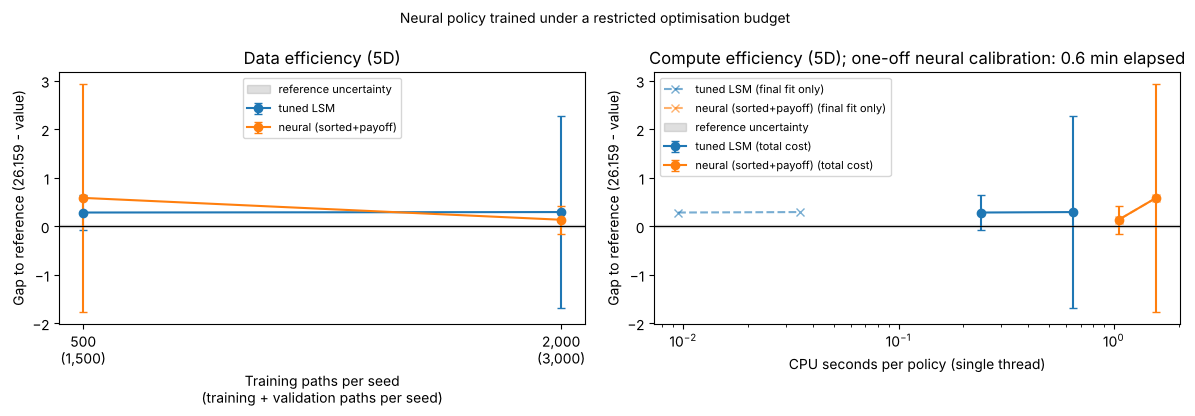

In [6]:
ref5 = PAPER_REFERENCES[5]
band = (ref5["value"] - ref5["high"], ref5["value"] - ref5["low"])
budgets = sorted(summary.budget.unique())
labels = {"lsm": "tuned LSM", f"nn_{MAIN_VARIANT}": f"neural ({MAIN_VARIANT})"}
colors = {"lsm": "tab:blue", f"nn_{MAIN_VARIANT}": "tab:orange"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for method, sub in summary.groupby("method"):
    sub = sub.sort_values("budget")
    err = np.vstack([sub.gap - sub.combined_ci_low, sub.combined_ci_high - sub.gap]) if sub.combined_ci_low.notna().all() else None
    c = colors[method]
    axes[0].errorbar(sub.budget, sub.gap, yerr=err, fmt="o-", capsize=3, color=c, label=labels[method])
    axes[1].errorbar(sub.selection_s, sub.gap, yerr=err, fmt="o-", capsize=3, color=c, label=labels[method] + " (total cost)")
    axes[1].plot(sub.train_s, sub.gap, "x--", color=c, alpha=0.6, label=labels[method] + " (final fit only)")
for ax in axes:
    ax.axhspan(*band, color="grey", alpha=0.25, label="reference uncertainty")
    ax.axhline(0, color="black", lw=0.8); ax.set_xscale("log"); ax.set_ylabel("Gap to reference (26.159 - value)")
    ax.legend(fontsize=8)
axes[0].set_xticks(budgets, [f"{b:,}\n({b + study['val']:,})" for b in budgets])
axes[0].minorticks_off()
axes[0].set(xlabel="Training paths per seed\n(training + validation paths per seed)", title="Data efficiency (5D)")
dev = frozen.get("development_elapsed_minutes", frozen.get("development_cost_cpu_minutes", float("nan")))
axes[1].set(xlabel="CPU seconds per policy (single thread)",
            title=f"Compute efficiency (5D); one-off neural calibration: {dev:.1f} min elapsed")
fig.suptitle(f"Neural policy trained under a {BUDGET_LABEL}", fontsize=10)
fig.tight_layout(); fig.savefig(OUT / "fig_gap_vs_data_and_compute.png", dpi=160); plt.show()

### 2.3 Representation ablation (2×2)
All four variants use the same frozen training protocol, so these are effects **under a common training budget** (Claim A: does the representation make the network learn faster?).
Whether the weakest variant eventually catches up with more steps (Claim B) is answered by notebook 02's diagnostic saturation curves, not here.
Contrasts are computed per seed on the same test paths, then summarised across seeds. Effects can interact, so the four cell means, the conditional effects and the interaction are all reported;
no fixed percentage of the improvement is attributed to either mechanism. Conclusions are specific to this architecture and training budget.
LSM already uses sorted, payoff-aware features. Neural settings are tuned on payoff-input variants, so the ablation measures representation effects under a protocol selected for those variants. This confounds any claim of an intrinsic representation advantage.


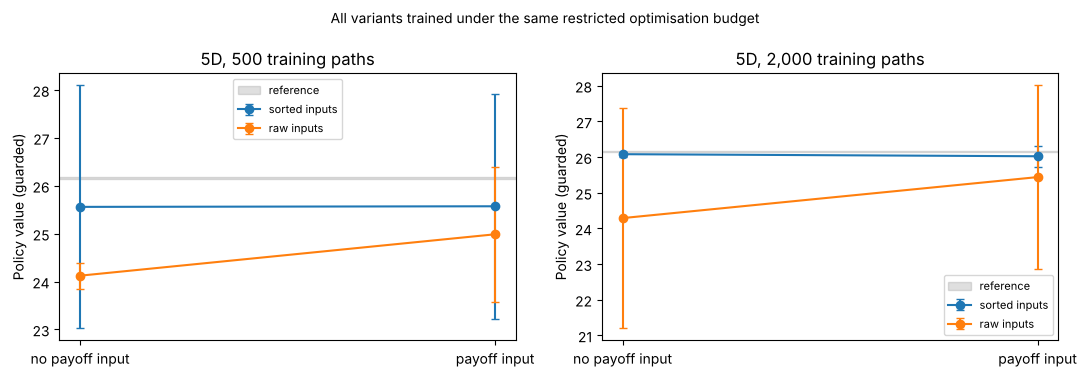

,budget,method,mean,ci_low,ci_high,seeds
0,500,nn_raw,24.1234,23.8523,24.3945,2
1,500,nn_raw+payoff,24.9878,23.5744,26.4011,2
2,500,nn_sorted,25.5600,23.0240,28.0960,2
3,500,nn_sorted+payoff,25.5726,23.2194,27.9258,2
4,2000,nn_raw,24.2896,21.1998,27.3795,2
5,2000,nn_raw+payoff,25.4388,22.8691,28.0085,2
6,2000,nn_sorted,26.0812,26.0075,26.1549,2
7,2000,nn_sorted+payoff,26.0231,25.7344,26.3117,2


,budget,contrast,mean,ci_low,ci_high,seeds,median_paired_se
0,500,interaction,-0.8518,-2.1768,0.4733,2,0.1083
1,500,payoff effect | raw,0.8644,-0.2779,2.0066,2,0.0846
2,500,payoff effect | sorted,0.0126,-0.1702,0.1954,2,0.0644
3,500,sorting effect | no payoff,1.4366,-0.8283,3.7015,2,0.1028
4,500,sorting effect | payoff,0.5848,-0.3550,1.5247,2,0.0912
5,2000,interaction,-1.2073,-1.5126,-0.9021,2,0.1032
6,2000,payoff effect | raw,1.1492,0.6290,1.6694,2,0.0852
7,2000,payoff effect | sorted,-0.0581,-0.2730,0.1568,2,0.0582
8,2000,sorting effect | no payoff,1.7916,-1.3720,4.9551,2,0.0987
9,2000,sorting effect | payoff,0.5842,-2.2741,3.4426,2,0.0796


In [7]:
abl_runs = runs[(runs.d == 5) & runs.guarded & runs.budget.isin(study["ablation_budgets"]) & runs.method.str.startswith("nn_")]
cells = across_seeds(abl_runs, ["budget", "method"], "value")
abl_pairs = pairs[(pairs.d == 5) & pairs.guarded & pairs.contrast.isin(list(ABLATION_CONTRASTS))]
effects = across_seeds(abl_pairs, ["budget", "contrast"], "diff").merge(
    abl_pairs.groupby(["budget", "contrast"]).paired_se.median().rename("median_paired_se").reset_index(),
    on=["budget", "contrast"])
cells.to_csv(OUT / "summary_ablation_cells.csv", index=False)
effects.to_csv(OUT / "summary_ablation_effects.csv", index=False)

fig, axes = plt.subplots(1, len(study["ablation_budgets"]), figsize=(5.5 * len(study["ablation_budgets"]), 3.8), squeeze=False)
for ax, b in zip(axes[0], study["ablation_budgets"]):
    c = cells[cells.budget == b].set_index("method")
    for sort_label in ("sorted", "raw"):
        names = [f"nn_{sort_label}", f"nn_{sort_label}+payoff"]
        if all(n in c.index for n in names):
            m = c.loc[names, "mean"].to_numpy()
            err = np.vstack([m - c.loc[names, "ci_low"], c.loc[names, "ci_high"] - m]) if c.loc[names, "ci_low"].notna().all() else None
            ax.errorbar([0, 1], m, yerr=err, fmt="o-", capsize=3, label=f"{sort_label} inputs")
    ax.axhspan(ref5["low"], ref5["high"], color="grey", alpha=0.25, label="reference")
    ax.set_xticks([0, 1], ["no payoff input", "payoff input"])
    ax.set(title=f"5D, {b:,} training paths", ylabel="Policy value (guarded)"); ax.legend(fontsize=8)
fig.suptitle(f"All variants trained under the same {BUDGET_LABEL}", fontsize=10)
fig.tight_layout(); fig.savefig(OUT / "fig_ablation.png", dpi=160); plt.show()
display(cells.round(4)); effects.round(4)

### 2.4 What the never-exercise guard changes
`guarded − unguarded` is an execution-level ablation of the *same* fitted models (earlier dates were trained against the guarded later policy).
Many guarded dates for a neural variant are a sign of undertraining and must be reported, not hidden.
The guard is asymmetric: neural checkpoint selection maximises validation gains over multiple checkpoints, whereas LSM guards a fitted date rule (with degree/ridge selection also using validation). Fresh development-path diagnostics in notebook 02 assess the resulting selection bias without changing guard decisions.


In [8]:
guard_pairs = pairs[pairs.contrast.str.endswith("guarded - unguarded")].copy()
guard_pairs["method"] = guard_pairs.contrast.str.split(":").str[0]
guard = across_seeds(guard_pairs, ["d", "budget", "method"], "diff").merge(
    runs[runs.guarded].groupby(["d", "budget", "method"]).n_guarded_dates.mean().rename("mean_guarded_dates").reset_index(),
    on=["d", "budget", "method"])
guard.to_csv(OUT / "summary_guard.csv", index=False)
by_date = dates.pivot_table(index=["d", "budget", "method"], columns="date", values="guard", aggfunc="mean")
display(guard.round(4))
print("Share of seeds in which the guard fired, by exercise date:")
by_date.round(2)

,d,budget,method,mean,ci_low,ci_high,seeds,mean_guarded_dates
0,2,2000,lsm,0.0147,-0.1164,0.1458,2,1.0
1,2,2000,nn_sorted+payoff,-0.0227,-0.3109,0.2655,2,0.5
2,5,500,lsm,0.0143,-0.0671,0.0956,2,1.5
3,5,500,nn_raw,0.0000,0.0000,0.0000,2,0.0
4,5,500,nn_raw+payoff,-0.0002,-0.0023,0.0019,2,1.5
5,5,500,nn_sorted,0.0098,-0.1145,0.1340,2,0.5
6,5,500,nn_sorted+payoff,-0.0424,-0.3322,0.2474,2,1.0
7,5,2000,lsm,0.0084,-1.6673,1.6841,2,2.0
8,5,2000,nn_raw,0.0000,0.0000,0.0000,2,0.0
9,5,2000,nn_raw+payoff,0.0006,-0.0075,0.0087,2,0.5


Share of seeds in which the guard fired, by exercise date:


date                         1    2    3    4    5    6    7    8
d budget method                                                  
2 2000   lsm               1.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
         nn_sorted+payoff  0.0  0.5  0.0  0.0  0.0  0.0  0.0  0.0
5 500    lsm               1.0  0.5  0.0  0.0  0.0  0.0  0.0  0.0
         nn_raw            0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
         nn_raw+payoff     0.5  0.5  0.5  0.0  0.0  0.0  0.0  0.0
         nn_sorted         0.5  0.0  0.0  0.0  0.0  0.0  0.0  0.0
         nn_sorted+payoff  0.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0
  2000   lsm               0.5  1.0  0.5  0.0  0.0  0.0  0.0  0.0
         nn_raw            0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
         nn_raw+payoff     0.5  0.0  0.0  0.0  0.0  0.0  0.0  0.0
         nn_sorted         0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
         nn_sorted+payoff  0.0  0.5  0.0  0.0  0.0  0.0  0.0  0.0

### 2.5 Generality check: 2D (and optional 10D)

In [9]:
other = runs[(runs.d != 5) & runs.guarded]
gen = across_seeds(other, ["d", "budget", "method"], "gap").rename(columns={"mean": "gap"}).merge(
    other.groupby(["d", "budget", "method"]).agg(value=("value", "mean"), median_test_se=("test_se", "median")).reset_index(),
    on=["d", "budget", "method"])
other_uncertainty = []
for (d, budget, method), sub in other.groupby(["d", "budget", "method"]):
    other_uncertainty.append(dict(d=d, budget=budget, method=method,
        **absolute_gap_uncertainty(sub.gap, sub.test_se)))
gen = gen.merge(pd.DataFrame(other_uncertainty), on=["d", "budget", "method"])
gen["reference"] = gen.d.map(lambda d: PAPER_REFERENCES[d]["value"])
gen["reference_ci"] = gen.d.map(lambda d: f"[{PAPER_REFERENCES[d]['low']}, {PAPER_REFERENCES[d]['high']}]")
gen["gap_inside_reference_band"] = [PAPER_REFERENCES[d]["value"] - PAPER_REFERENCES[d]["high"] <= g <= PAPER_REFERENCES[d]["value"] - PAPER_REFERENCES[d]["low"]
                                    for d, g in zip(gen.d, gen.gap)]
gen.to_csv(OUT / "summary_other_dimensions.csv", index=False)
gen.round(4)

,d,budget,method,gap,ci_low,ci_high,seeds,value,median_test_se,reference,reference_ci,gap_inside_reference_band
0,2,2000,lsm,0.3274,-0.5104,1.1652,2,13.5746,0.1091,13.902,"[13.88, 13.91]",False
1,2,2000,nn_sorted+payoff,0.1876,-0.6934,1.0686,2,13.7144,0.1080,13.902,"[13.88, 13.91]",False


## 3. Prespecified policy dual experiments
We evaluate guarded LSM and sorted+payoff neural policies at every 5D budget for seeds 0–2; all remaining ablation variants at the two ablation budgets for seed 0; and both methods in 2D at its configured budget for seed 0. Quick mode uses the available seeds and reduced nested samples only for smoke checks. Policies are deterministically refitted on the original training/validation paths; no test or nested estimate selects a policy.

The M3 sizing evidence supports 2,000 outer and 3,200 inner paths for two tested policies, not every policy here. A doubled-inner spot check is prescribed for both main methods at the largest 5D budget, seed 0. Other policies retain unmeasured inner bias. We report paired primal–dual gaps, outer normal intervals and raw paired samples. Finite-inner upper estimates bound in expectation, never pathwise; their intervals do not remove inner bias. Shared outer streams aid comparisons but do not make results independent across policies. No main-study settings may be adjusted from these results. H3 precision and stability remain hypotheses to evaluate, not automatic passes.

Each complete policy/budget job is saved separately with source/configuration provenance. An interrupted job is rerun; existing incompatible evidence is retained under a different hash namespace. Full experiments remain controller-owned and subject to the M5 budget gate.


In [ ]:
from dual import policy_dual

dual_outer, dual_inner = (32, 64) if MODE == "quick" else (2000, 3200)
dual_seeds = [s for s in (0, 1, 2) if s in study["seeds"]]
dual_plan = [(5, b, s, method, dual_inner)
             for b in study["budgets"] for s in dual_seeds
             for method in ("lsm", MAIN_VARIANT)]
dual_plan += [(5, b, 0, variant, dual_inner)
              for b in study["ablation_budgets"] for variant in VARIANTS if variant != MAIN_VARIANT]
dual_plan += [(2, study["case_2d"]["budget"], 0, method, dual_inner)
              for method in ("lsm", MAIN_VARIANT)]
dual_plan += [(5, max(study["budgets"]), 0, method, 2*dual_inner)
              for method in ("lsm", MAIN_VARIANT)]
dual_spec = dict(provenance=calibration_provenance(MODE), neural=frozen["neural"],
                 plan=dual_plan, outer=dual_outer, chunk=16, memory_mb=256,
                 training_validation=study, base_seed=BASE)
dual_folder = OUT / ("study-dual-" + stable_hash(dual_spec))
dual_folder.mkdir(exist_ok=True)
(dual_folder / "spec.json").write_text(json.dumps(dual_spec, indent=2))
dual_rows = []
for d, budget, seed, method, inner in dual_plan:
    stem = f"{d}d-{budget}-{seed}-{method}-{inner}"
    record_path = dual_folder / (stem + ".json")
    sample_path = dual_folder / (stem + ".npz")
    if record_path.exists() and sample_path.exists():
        dual_rows.append(json.loads(record_path.read_text()))
        continue
    o = cases[d]
    train = gbm_paths(o, budget, seed_for(BASE, "train", d, seed))
    val = gbm_paths(o, study["val"], seed_for(BASE, "val", d, seed))
    t0 = time.perf_counter()
    if method == "lsm":
        policy = select_lsm(o, train, val)[0]
    else:
        policy = fit_neural(o, train, val, with_variant(settings, method),
                            seed=seed_for(BASE, "init", d, seed))
    # Deliberate common outer streams across budgets/methods for each training seed.
    result = policy_dual(o, policy, outer=dual_outer, inner=inner,
                         base_seed=BASE, seed=86000+seed, outer_chunk=16, memory_mb=256)
    row = dict(d=d, budget=budget, seed=seed, method=method, inner=inner,
               seconds=time.perf_counter()-t0, metadata=result["metadata"],
               **{key: result[key] for key in ("lower", "upper", "gap")})
    np.savez_compressed(sample_path, lower=result["lower_samples"], upper=result["upper_samples"])
    temporary = record_path.with_suffix(".json.pending")
    temporary.write_text(json.dumps(row, indent=2, default=float))
    temporary.replace(record_path)
    dual_rows.append(row)
    print(stem, "gap:", row["gap"], flush=True)
dual_table = pd.DataFrame([dict(d=r["d"], budget=r["budget"], seed=r["seed"],
    method=r["method"], inner=r["inner"], **{f"{k}_{field}": r[k][field]
    for k in ("lower", "upper", "gap") for field in ("mean", "se", "ci_low", "ci_high")})
    for r in dual_rows])
dual_table.to_csv(dual_folder / "summary.csv", index=False)
display(dual_table)
# Compare doubled-inner jobs using paired outer-path differences, retaining inner noise.
stability = []
for method in ("lsm", MAIN_VARIANT):
    stem = f"5d-{max(study['budgets'])}-0-{method}-"
    with np.load(dual_folder / (stem+str(dual_inner)+".npz")) as a, np.load(
            dual_folder / (stem+str(2*dual_inner)+".npz")) as b:
        assert np.array_equal(a["lower"], b["lower"]), "outer paths differ"
        change = b["upper"]-a["upper"]
        mean, se, lo, hi = mean_ci(change)
        stability.append(dict(method=method, doubled_minus_base=mean, paired_se=se,
                              ci_low=lo, ci_high=hi))
pd.DataFrame(stability).to_csv(dual_folder / "inner_stability.csv", index=False)
display(pd.DataFrame(stability))


## 4. Interpretation checklist (fill in after the full run)
1. **Was the neural policy adequately trained?** Check notebook 02's saturation flag and `at_limit_share`, and the guard table above. If not saturated, say so first.
2. **Data efficiency:** at which budget (if any) is the neural gap within the paired uncertainty of LSM's? Use the paired table (2.1), not overlapping intervals.
3. **Compute efficiency:** how much more CPU time does the neural policy need for the same gap, before and after counting the one-off calibration?
4. **Mechanism:** size and interval of the payoff effect, the sorting effect, and their interaction at each ablation budget.
5. **Limits:** fixed 5k validation budget; Black–Scholes testbed; finite-inner dual bias and outer Monte Carlo uncertainty; one architecture; results conditional on the shared test set.

A negative result (LSM at least as good at every budget) is a valid finding and should be reported plainly.